In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
def print_title(text):
    print('='*50)
    print(text)
    print('='*50)

In [3]:
print_title('load the dataset')

df=sns.load_dataset('titanic')

load the dataset


# **EDA**

In [ ]:
print_title('1. CADRAGE')

print(f'Target: survived (binary)')
print(f'Rows: {df.shape[0]}')
print(f'Columns: {df.shape[1]}')

column_types = { 'survived': 'Boolean', 
                'pclass': 'Ordinal', 
                'sex': 'Nominal', 
                'age': 'Numerical', 
                'sibsp': 'Numerical', 
                'parch': 'Numerical', 
                'fare': 'Numerical', 
                'embarked': 'Nominal', 
                'class': 'Ordinal', 
                'who': 'Nominal', 
                'adult_male': 'Boolean', 
                'deck': 'Nominal', 
                'embark_town': 'Nominal', 
                'alive': 'Boolean', 
                'alone': 'Boolean' }

for column, kind in column_types.items():
    print(f'{column}: {kind}')

1. CADRAGE
Target: survived (binary)
Rows: 891
Columns: 15
survived: Boolean
pclass: Ordinal
sex: Nominal
age: Numerical
sibsp: Numerical
parch: Numerical
fare: Numerical
embarked: Nominal
class: Ordinal
who: Nominal
adult_male: Boolean
deck: Nominal
embark_town: Nominal
alive: Boolean
alone: Boolean


In [22]:
print_title('REDUNDANT COLUMNS')

print(pd.crosstab(df['class'], df['pclass']))
print(pd.crosstab(df['embarked'], df['embark_town']))
print(pd.crosstab(df['survived'], df['alive']))
print(pd.crosstab(df['sex'], df['adult_male']))

REDUNDANT COLUMNS
pclass    1    2    3
class                
First   216    0    0
Second    0  184    0
Third     0    0  491
embark_town  Cherbourg  Queenstown  Southampton
embarked                                       
C                  168           0            0
Q                    0          77            0
S                    0           0          644
alive      no  yes
survived          
0         549    0
1           0  342
adult_male  False  True 
sex                     
female        314      0
male           40    537


In [ ]:
print_title('data quality')

missing = pd.DataFrame({
    'Missing Count': df.isna().sum(),
    'Missing Percentage': (df.isna().mean() * 100).round(2)
})

print(missing.sort_values('Missing Percentage', ascending=False))

data quality


,Missing Count,Missing Percentage
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


In [11]:
print_title('DUPLICATED ROWS')

print(f'Duplicated rows: {df.duplicated().sum()}')

DUPLICATED ROWS
Duplicated rows: 107


In [12]:
print_title('IMPOSSIBLE VALUES')

print(f'Age <= 0: {(df["age"] <= 0).sum()}')
print(f'Fare < 0: {(df["fare"] < 0).sum()}')
print(f'SibSp < 0: {(df["sibsp"] < 0).sum()}')
print(f'Parch < 0: {(df["parch"] < 0).sum()}')
print(f'Invalid survived: {(~df["survived"].isin([0, 1])).sum()}')

IMPOSSIBLE VALUES
Age <= 0: 0
Fare < 0: 0
SibSp < 0: 0
Parch < 0: 0
Invalid survived: 0


In [25]:
print_title('UNIVARIATE NUMERICAL ANALYSIS')

print(
    df[['age', 'fare']].agg(['mean', 
                             'median', 
                             'min',
                             'max', 
                             'skew' ]) )

UNIVARIATE NUMERICAL ANALYSIS
              age        fare
mean    29.699118   32.204208
median  28.000000   14.454200
min      0.420000    0.000000
max     80.000000  512.329200
skew     0.389108    4.787317


In [14]:
print_title('FARE OUTLIERS - IQR')

Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['fare'] < lower_bound) |
    (df['fare'] > upper_bound)
]

print(f'Q1: {Q1:.2f}')
print(f'Q3: {Q3:.2f}')
print(f'IQR: {IQR:.2f}')
print(f'Lower bound: {lower_bound:.2f}')
print(f'Upper bound: {upper_bound:.2f}')
print(f'Number of fare outliers: {len(outliers)}')

print(f'\nOriginal fare skewness: {df["fare"].skew():.2f}')
print(f'Log-transformed fare skewness: {np.log1p(df["fare"]).skew():.2f}')

FARE OUTLIERS - IQR
Q1: 7.91
Q3: 31.00
IQR: 23.09
Lower bound: -26.72
Upper bound: 65.63
Number of fare outliers: 116

Original fare skewness: 4.79
Log-transformed fare skewness: 0.39


In [24]:
print_title('UNIVARIATE CATEGORICAL ANALYSIS')

for column in ['embarked', 'pclass', 'sex', 'alone']:
    print(f'\n{column}:')
    print(
        pd.DataFrame({
            'Count': df[column].value_counts(dropna=False),
            'Percentage': (
                df[column].value_counts(normalize=True, dropna=False) * 100
            ).round(2)
        })
    )

UNIVARIATE CATEGORICAL ANALYSIS

embarked:
          Count  Percentage
embarked                   
S           644       72.28
C           168       18.86
Q            77        8.64
NaN           2        0.22

pclass:
        Count  Percentage
pclass                   
3         491       55.11
1         216       24.24
2         184       20.65

sex:
        Count  Percentage
sex                      
male      577       64.76
female    314       35.24

alone:
       Count  Percentage
alone                   
True     537       60.27
False    354       39.73


TARGET BALANCE
          Count  Percentage
survived                   
0           549       61.62
1           342       38.38


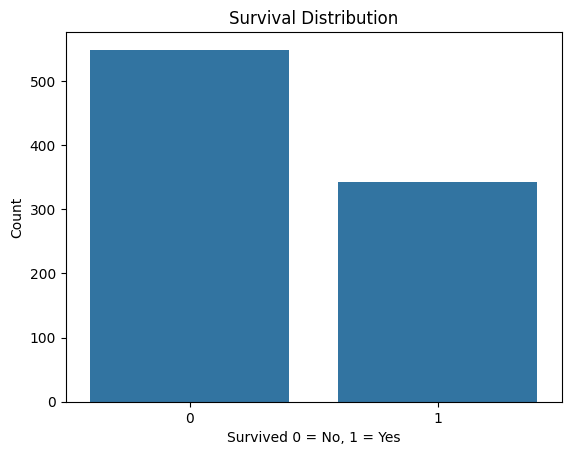

In [21]:
print_title('TARGET BALANCE')

print(
    pd.DataFrame({
        'Count': df['survived'].value_counts().sort_index(),
        'Percentage': (
            df['survived'].value_counts(normalize=True).sort_index() * 100
        ).round(2)
    })
)

sns.countplot(data=df, x='survived')
plt.title('Survival Distribution')
plt.xlabel('Survived 0 = No, 1 = Yes')
plt.ylabel('Count')
plt.show()

In [23]:
print_title('9. MISSING AGE AND TARGET')

df['age_missing'] = df['age'].isna()

print('Missing age by passenger class (%):')
print(
    (df.groupby('pclass')['age_missing'].mean() * 100)
    .round(2)
)

print('\nMissing age by survival (%):')
print(
    (df.groupby('survived')['age_missing'].mean() * 100)
    .round(2)
)

9. MISSING AGE AND TARGET
Missing age by passenger class (%):
pclass
1    13.89
2     5.98
3    27.70
Name: age_missing, dtype: float64

Missing age by survival (%):
survived
0    22.77
1    15.20
Name: age_missing, dtype: float64
